In [ ]:

import os
import requests
import zipfile

arquivo = "xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip"

url = (
    "https://raw.githubusercontent.com/"
    "thiago-starikoff-academico/TPAE-2-projeto/main/"
    + arquivo
)

destino = "/content/" + arquivo

os.makedirs("/content", exist_ok=True)

if not os.path.isfile(destino) or not zipfile.is_zipfile(destino):
    resposta = requests.get(url, timeout=120)
    resposta.raise_for_status()

    with open(destino, "wb") as f:
        f.write(resposta.content)

assert zipfile.is_zipfile(destino), "O ZIP não é válido."

print("Licenciamento pronto:", destino)


Licenciamento pronto: /content/xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip


# TPAE II — Entrega 5 | Aquisição, limpeza e tratamento de dados

Equipe 06 — Thiago Ramirez Balotta Starikoff, João Marcos Nery da Silva e Cauã Antero do Nascimento.

**Objetivo:** integrar população urbana/rural, alfabetização e renda per capita dos 223 municípios da Paraíba, com dados do Censo 2022/IBGE. Fontes: agregados por setores, tabela 2.1, tabelas 9543 e 10295. Arquivo final: `base_municipal_pb_tratada.csv`.


## 1. Aquisição reproduzível pelo GitHub
Os quatro arquivos originais são lidos do repositório público, sem upload manual.

In [ ]:
import os
import subprocess
import zipfile
import pandas as pd

repositorio = "https://github.com/thiago-starikoff-academico/TPAE-2-projeto.git"
pasta = "/content/TPAE-2-projeto"

if os.path.isdir(os.path.join(pasta, ".git")):
    subprocess.run(["git", "-C", pasta, "pull"], check=True)
else:
    subprocess.run(["git", "clone", repositorio, pasta], check=True)

pasta_raw = os.path.join(pasta, "data", "raw")
pasta_extraida = "/content/dados_ibge"
os.makedirs(pasta_extraida, exist_ok=True)

for nome in [
    "Agregados_por_setores_basico_BR_20260520.zip",
    "2_1_Populacao_residente_Area_territorial_Densidade_demografica_xlsx.zip"
]:
    with zipfile.ZipFile(os.path.join(pasta_raw, nome)) as arquivo:
        arquivo.extractall(pasta_extraida)

arquivo_setores = os.path.join(pasta_extraida, "Agregados_por_setores_basico_BR.csv")
arquivo_populacao = os.path.join(pasta_extraida, "tabela_2_1_PB.xlsx")
arquivo_alfabetizacao = os.path.join(pasta, "Tabela 9543.xlsx")
arquivo_renda = os.path.join(pasta, "Tabela 10295.xlsx")

for caminho in [arquivo_setores, arquivo_populacao, arquivo_alfabetizacao, arquivo_renda]:
    assert os.path.isfile(caminho), f"Arquivo não encontrado: {caminho}"
print("Quatro arquivos originais encontrados e extraídos.")


Quatro arquivos originais encontrados e extraídos.


## 2. Diagnóstico e tratamento dos setores censitários

In [ ]:
import pandas as pd

caminho = "/content/dados_ibge/Agregados_por_setores_basico_BR.csv"

setores = pd.read_csv(
    caminho,
    sep=";",
    encoding="latin1",
    low_memory=False
)

print("Dimensões:", setores.shape)
print("Colunas:", setores.columns.tolist()[:15])

Dimensões: (468099, 38)
Colunas: ['CD_SETOR', 'SITUACAO', 'CD_SIT', 'CD_TIPO', 'AREA_KM2', 'CD_REGIAO', 'NM_REGIAO', 'CD_UF', 'NM_UF', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST', 'CD_SUBDIST', 'NM_SUBDIST']


In [ ]:
setores_pb = setores[setores["CD_UF"] == 25].copy()

print("Setores da Paraíba:", len(setores_pb))
print("Municípios:", setores_pb["CD_MUN"].nunique())
print("\nSituação dos setores:")
print(setores_pb["SITUACAO"].value_counts(dropna=False))

print("\nCódigos de setores duplicados:",
      setores_pb["CD_SETOR"].duplicated().sum())

Setores da Paraíba: 9639
Municípios: 223

Situação dos setores:
SITUACAO
Urbana    6434
Rural     3200
NaN          5
Name: count, dtype: int64

Códigos de setores duplicados: 0


In [ ]:
setores_sem_situacao = setores_pb[
    setores_pb["SITUACAO"].isna()
]

print(setores_sem_situacao[
    ["CD_SETOR", "CD_MUN", "NM_MUN", "SITUACAO", "v0001"]
].to_string(index=False))

       CD_SETOR  CD_MUN      NM_MUN SITUACAO  v0001
250250805000038 2502508   Boqueirão      NaN      0
250320905000119 2503209    Cabedelo      NaN      0
250750705002107 2507507 João Pessoa      NaN      0
251340605000036 2513406 Santa Luzia      NaN      0
251340605000039 2513406 Santa Luzia      NaN      0


In [ ]:
setores_pb_tratados = setores_pb[
    setores_pb["SITUACAO"].isin(["Urbana", "Rural"])
].copy()

print("Registros antes:", len(setores_pb))
print("Registros depois:", len(setores_pb_tratados))
print("Registros excluídos:", len(setores_pb) - len(setores_pb_tratados))

print(
    "População antes:",
    setores_pb["v0001"].sum()
)

print(
    "População depois:",
    setores_pb_tratados["v0001"].sum()
)

Registros antes: 9639
Registros depois: 9634
Registros excluídos: 5
População antes: 3974687
População depois: 3974687


In [ ]:
pop_situacao = (
    setores_pb_tratados
    .groupby(["CD_MUN", "NM_MUN", "SITUACAO"])["v0001"]
    .sum()
    .reset_index()
)

print("Municípios:", pop_situacao["CD_MUN"].nunique())
print("População agregada:", pop_situacao["v0001"].sum())

print("\nPrimeiras linhas:")
print(pop_situacao.head(10))

Municípios: 223
População agregada: 3974687

Primeiras linhas:
    CD_MUN         NM_MUN SITUACAO  v0001
0  2500106    Água Branca    Rural   4841
1  2500106    Água Branca   Urbana   4494
2  2500205         Aguiar    Rural   2154
3  2500205         Aguiar   Urbana   2849
4  2500304  Alagoa Grande    Rural   9332
5  2500304  Alagoa Grande   Urbana  16730
6  2500403    Alagoa Nova    Rural   9428
7  2500403    Alagoa Nova   Urbana  11585
8  2500502      Alagoinha    Rural   4159
9  2500502      Alagoinha   Urbana   9566


## 3. Conferência com a população oficial do IBGE
A comparação serve como controle de qualidade, não como substituição dos valores setoriais.

In [ ]:
tabela_ibge = pd.read_excel(arquivo_populacao, header=None)
pop_oficial = tabela_ibge.iloc[5:, :2].copy()
pop_oficial.columns = ["municipio", "populacao_oficial"]
pop_oficial["municipio"] = (pop_oficial["municipio"].astype(str)
    .str.replace(r"\s*\(PB\)$", "", regex=True).str.strip())
pop_oficial["populacao_oficial"] = pd.to_numeric(
    pop_oficial["populacao_oficial"], errors="coerce")
pop_oficial = pop_oficial.dropna(subset=["populacao_oficial"]).copy()

pop_setores = (pop_situacao.groupby("NM_MUN", as_index=False)["v0001"].sum()
    .rename(columns={"NM_MUN": "municipio", "v0001": "populacao_setores"}))
comparacao = pop_oficial.merge(pop_setores, on="municipio", how="outer", indicator=True,
                              validate="one_to_one")
comparacao["diferenca"] = comparacao["populacao_setores"] - comparacao["populacao_oficial"]
print("Municípios comparados:", len(comparacao))
print("Sem correspondência:", (comparacao["_merge"] != "both").sum())
print("Com diferença:", comparacao["diferenca"].fillna(0).ne(0).sum())
print("Diferença total:", comparacao["diferenca"].sum())
print(comparacao.loc[comparacao["diferenca"].fillna(0).ne(0),
                    ["municipio", "populacao_oficial", "populacao_setores", "diferenca"]])


Municípios comparados: 223
Sem correspondência: 0
Com diferença: 2
Diferença total: 192.0
   municipio  populacao_oficial  populacao_setores  diferenca
6   Alhandra            21713.0              21730       17.0
90   Jacaraú            14302.0              14477      175.0


## 4. Consolidação municipal

In [ ]:
pop_municipios = pop_situacao.pivot(
    index=["CD_MUN", "NM_MUN"],
    columns="SITUACAO",
    values="v0001"
).reset_index()

pop_municipios.columns.name = None

pop_municipios = pop_municipios.rename(columns={
    "CD_MUN": "codigo_ibge",
    "NM_MUN": "municipio",
    "Rural": "populacao_rural",
    "Urbana": "populacao_urbana"
})

pop_municipios["populacao_total"] = (
    pop_municipios["populacao_rural"] +
    pop_municipios["populacao_urbana"]
)

pop_municipios["percentual_rural"] = (
    pop_municipios["populacao_rural"] /
    pop_municipios["populacao_total"] * 100
).round(2)

print("Dimensões:", pop_municipios.shape)
print("População total:", pop_municipios["populacao_total"].sum())
print("\nPrimeiras linhas:")
print(pop_municipios.head())

Dimensões: (223, 6)
População total: 3974687

Primeiras linhas:
  codigo_ibge      municipio  populacao_rural  populacao_urbana  \
0     2500106    Água Branca             4841              4494   
1     2500205         Aguiar             2154              2849   
2     2500304  Alagoa Grande             9332             16730   
3     2500403    Alagoa Nova             9428             11585   
4     2500502      Alagoinha             4159              9566   

   populacao_total  percentual_rural  
0             9335             51.86  
1             5003             43.05  
2            26062             35.81  
3            21013             44.87  
4            13725             30.30  


## 5. Alfabetização e integração

In [ ]:
alfabetizacao_bruta = pd.read_excel(arquivo_alfabetizacao, header=None)
print("Dimensões:", alfabetizacao_bruta.shape)


Dimensões: (233, 2)


In [ ]:
alfabetizacao = alfabetizacao_bruta.iloc[9:, :2].copy()

alfabetizacao.columns = [
    "municipio",
    "taxa_alfabetizacao"
]

alfabetizacao["municipio"] = (
    alfabetizacao["municipio"]
    .astype(str)
    .str.replace(r"\s*\(PB\)$", "", regex=True)
    .str.strip()
)

alfabetizacao["taxa_alfabetizacao"] = pd.to_numeric(
    alfabetizacao["taxa_alfabetizacao"],
    errors="coerce"
)

# Manter apenas municípios presentes na base principal
alfabetizacao = alfabetizacao[
    alfabetizacao["municipio"].isin(pop_municipios["municipio"])
].copy()

print("Municípios:", len(alfabetizacao))
print("Valores ausentes:", alfabetizacao["taxa_alfabetizacao"].isna().sum())
print("Municípios duplicados:", alfabetizacao["municipio"].duplicated().sum())

print("\nPrimeiras linhas:")
print(alfabetizacao.head())

Municípios: 223
Valores ausentes: 0
Municípios duplicados: 0

Primeiras linhas:
        municipio  taxa_alfabetizacao
9     Água Branca               81.32
10         Aguiar               69.50
11  Alagoa Grande               72.55
12    Alagoa Nova               78.21
13      Alagoinha               73.45


In [ ]:
# Conferir correspondência entre as bases
faltantes = set(pop_municipios["municipio"]) - set(alfabetizacao["municipio"])

print("Municípios sem alfabetização:", len(faltantes))
print("Taxas fora do intervalo 0 a 100:",
      (~alfabetizacao["taxa_alfabetizacao"].between(0, 100)).sum())

# Integrar os dados
base_municipal = pop_municipios.merge(
    alfabetizacao,
    on="municipio",
    how="left",
    validate="one_to_one"
)

print("\nDimensões da base:", base_municipal.shape)
print("Alfabetização ausente após integração:",
      base_municipal["taxa_alfabetizacao"].isna().sum())

print("\nPrimeiras linhas:")
print(base_municipal.head())

Municípios sem alfabetização: 0
Taxas fora do intervalo 0 a 100: 0

Dimensões da base: (223, 7)
Alfabetização ausente após integração: 0

Primeiras linhas:
  codigo_ibge      municipio  populacao_rural  populacao_urbana  \
0     2500106    Água Branca             4841              4494   
1     2500205         Aguiar             2154              2849   
2     2500304  Alagoa Grande             9332             16730   
3     2500403    Alagoa Nova             9428             11585   
4     2500502      Alagoinha             4159              9566   

   populacao_total  percentual_rural  taxa_alfabetizacao  
0             9335             51.86               81.32  
1             5003             43.05               69.50  
2            26062             35.81               72.55  
3            21013             44.87               78.21  
4            13725             30.30               73.45  


## 6. Renda per capita e integração

In [ ]:
renda_bruta = pd.read_excel(arquivo_renda, header=None)
print("Dimensões:", renda_bruta.shape)


Dimensões: (232, 2)


In [ ]:
renda = renda_bruta.iloc[8:, :2].copy()

renda.columns = [
    "municipio",
    "renda_per_capita"
]

renda["municipio"] = (
    renda["municipio"]
    .astype(str)
    .str.replace(r"\s*\(PB\)$", "", regex=True)
    .str.strip()
)

renda["renda_per_capita"] = pd.to_numeric(
    renda["renda_per_capita"],
    errors="coerce"
)

# Manter apenas municípios da base principal
renda = renda[
    renda["municipio"].isin(base_municipal["municipio"])
].copy()

print("Municípios:", len(renda))
print("Valores ausentes:", renda["renda_per_capita"].isna().sum())
print("Municípios duplicados:", renda["municipio"].duplicated().sum())

print("\nPrimeiras linhas:")
print(renda.head())

Municípios: 223
Valores ausentes: 0
Municípios duplicados: 0

Primeiras linhas:
        municipio  renda_per_capita
8     Água Branca            771.95
9          Aguiar            737.35
10  Alagoa Grande            725.37
11    Alagoa Nova            726.13
12      Alagoinha            687.49


In [ ]:
# Verificar correspondência entre os municípios
faltantes_renda = (
    set(base_municipal["municipio"]) -
    set(renda["municipio"])
)

print("Municípios sem renda:", len(faltantes_renda))
print("Rendas negativas:", (renda["renda_per_capita"] < 0).sum())

# Integrar renda à base municipal
base_municipal = base_municipal.merge(
    renda,
    on="municipio",
    how="left",
    validate="one_to_one"
)

print("\nDimensões da base final:", base_municipal.shape)
print(
    "Rendas ausentes após integração:",
    base_municipal["renda_per_capita"].isna().sum()
)

print("\nPrimeiras linhas:")
print(base_municipal.head())

Municípios sem renda: 0
Rendas negativas: 0

Dimensões da base final: (223, 8)
Rendas ausentes após integração: 0

Primeiras linhas:
  codigo_ibge      municipio  populacao_rural  populacao_urbana  \
0     2500106    Água Branca             4841              4494   
1     2500205         Aguiar             2154              2849   
2     2500304  Alagoa Grande             9332             16730   
3     2500403    Alagoa Nova             9428             11585   
4     2500502      Alagoinha             4159              9566   

   populacao_total  percentual_rural  taxa_alfabetizacao  renda_per_capita  
0             9335             51.86               81.32            771.95  
1             5003             43.05               69.50            737.35  
2            26062             35.81               72.55            725.37  
3            21013             44.87               78.21            726.13  
4            13725             30.30               73.45            687.49  


## 7. Testes de integridade

In [ ]:
print("Dimensões:", base_municipal.shape)

print("\nValores ausentes por coluna:")
print(base_municipal.isna().sum())

print("\nMunicípios duplicados:",
      base_municipal["municipio"].duplicated().sum())

print("Códigos IBGE duplicados:",
      base_municipal["codigo_ibge"].duplicated().sum())

print("Populações negativas:",
      (base_municipal[
          ["populacao_rural", "populacao_urbana", "populacao_total"]
      ] < 0).sum().sum())

print("Totais populacionais inconsistentes:",
      (
          base_municipal["populacao_rural"] +
          base_municipal["populacao_urbana"] !=
          base_municipal["populacao_total"]
      ).sum())

print("Percentuais rurais inválidos:",
      (~base_municipal["percentual_rural"].between(0, 100)).sum())

print("Taxas de alfabetização inválidas:",
      (~base_municipal["taxa_alfabetizacao"].between(0, 100)).sum())

print("Rendas negativas:",
      (base_municipal["renda_per_capita"] < 0).sum())

print("\nPopulação total:",
      base_municipal["populacao_total"].sum())

Dimensões: (223, 8)

Valores ausentes por coluna:
codigo_ibge           0
municipio             0
populacao_rural       0
populacao_urbana      0
populacao_total       0
percentual_rural      0
taxa_alfabetizacao    0
renda_per_capita      0
dtype: int64

Municípios duplicados: 0
Códigos IBGE duplicados: 0
Populações negativas: 0
Totais populacionais inconsistentes: 0
Percentuais rurais inválidos: 0
Taxas de alfabetização inválidas: 0
Rendas negativas: 0

População total: 3974687


In [ ]:
assert len(base_municipal) == 223
assert base_municipal.shape[1] == 8
assert not base_municipal.isna().any().any()
assert not base_municipal["codigo_ibge"].duplicated().any()
assert not base_municipal["municipio"].duplicated().any()
assert (base_municipal["populacao_rural"] + base_municipal["populacao_urbana"] == base_municipal["populacao_total"]).all()
assert base_municipal["percentual_rural"].between(0, 100).all()
assert base_municipal["taxa_alfabetizacao"].between(0, 100).all()
assert (base_municipal["renda_per_capita"] >= 0).all()
assert (base_municipal[["populacao_rural", "populacao_urbana", "populacao_total"]] >= 0).all().all()
assert (comparacao["_merge"] == "both").all()
print("Todos os testes de integridade passaram.")


Todos os testes de integridade passaram.


## 8. Exportação e resumo final
O arquivo CSV tratado é salvo em `/content` e pode ser baixado pelo painel de arquivos do Colab.

In [ ]:
base_municipal.to_csv(
    "/content/base_municipal_pb_tratada.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo exportado com sucesso!")
print("Dimensões:", base_municipal.shape)

Arquivo exportado com sucesso!
Dimensões: (223, 8)


### Limitações documentadas
- Cinco setores da Paraíba sem classificação urbana/rural foram excluídos; todos possuíam população zero.
- A soma populacional setorial é 3.974.687, enquanto a tabela oficial registra 3.974.495: diferença de 192 habitantes, localizada em Alhandra (17) e Jacaraú (175). Os valores foram preservados e a divergência deve constar no relatório de qualidade.
- Alfabetização: percentual da população com 15 anos ou mais. Renda: rendimento nominal mensal domiciliar per capita em reais, referente a 2022. Não são medidas intercambiáveis.


## 9. Ampliação da base: telecomunicações e demografia

As etapas originais acima foram preservadas. As etapas abaixo exigem o envio ao Colab dos arquivos `xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip` e `empregados_mun_PB.xlsx`.

As estações licenciadas não são uma medida direta de cobertura ou qualidade da internet. A tabela demográfica selecionada mede pessoas com 10 anos ou mais, não pessoas empregadas. `rede_fixa_predominante` fica como “Não informado” por ausência dessa variável nas fontes.


In [ ]:

import os

print("Arquivos disponíveis no Colab:")
for arquivo in os.listdir("/content"):
    print(arquivo)


Arquivos disponíveis no Colab:
.config
empregados_mun_PB.xlsx
base_municipal_pb_tratada.csv
TPAE-2-projeto
base_municipal_pb_tratada_ATUALIZADA.csv
dados_ibge
xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip
sample_data


In [122]:

import pandas as pd
import zipfile
import os
import requests

# Repositório do projeto
github = (
    "https://raw.githubusercontent.com/"
    "thiago-starikoff-academico/TPAE-2-projeto/main/"
)

# Função para baixar arquivos que não estão no Colab
def obter_arquivo(nome):
    caminho = "/content/" + nome

    if not os.path.isfile(caminho):
        print("Baixando:", nome)

        resposta = requests.get(github + nome, timeout=120)
        resposta.raise_for_status()

        with open(caminho, "wb") as arquivo:
            arquivo.write(resposta.content)

    print("Arquivo disponível:", nome)
    return caminho


# 1. Abrir a base municipal original
caminho_base = obter_arquivo("base_municipal_pb_tratada.csv")

base = pd.read_csv(caminho_base, dtype={"codigo_ibge": str})


# 2. Baixar e abrir o licenciamento das antenas
nome_zip = "xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip"

caminho_zip = obter_arquivo(nome_zip)

if not zipfile.is_zipfile(caminho_zip):
    raise ValueError("O arquivo de licenciamento não é um ZIP válido.")

with zipfile.ZipFile(caminho_zip, "r") as zip_ref:

    arquivos_excel = [
        nome for nome in zip_ref.namelist()
        if nome.lower().endswith(".xlsx")
    ]

    if not arquivos_excel:
        raise ValueError("Nenhum arquivo Excel encontrado no ZIP.")

    print("Excel encontrado no ZIP:", arquivos_excel)

    with zip_ref.open(arquivos_excel[0]) as arquivo:
        antenas = pd.read_excel(arquivo)


# 3. Baixar e abrir os dados demográficos
caminho_demografia = obter_arquivo("empregados_mun_PB.xlsx")

demografia = pd.read_excel(caminho_demografia)


# 4. Conferir a estrutura dos dados
print("\nBASE ORIGINAL:", base.shape)
print("Colunas:", base.columns.tolist())

print("\nANTENAS:", antenas.shape)
print("Colunas:", antenas.columns.tolist())
print(antenas.head(3).to_string())

print("\nDEMOGRAFIA:", demografia.shape)
print("Colunas:", demografia.columns.tolist())
print(demografia.head(8).to_string())

print("\nArquivos carregados com sucesso!")


Arquivo disponível: base_municipal_pb_tratada.csv
Arquivo disponível: xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip
Excel encontrado no ZIP: ['xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.xlsx']
Arquivo disponível: empregados_mun_PB.xlsx

BASE ORIGINAL: (223, 8)
Colunas: ['codigo_ibge', 'municipio', 'populacao_rural', 'populacao_urbana', 'populacao_total', 'percentual_rural', 'taxa_alfabetizacao', 'renda_per_capita']

ANTENAS: (54170, 41)
Colunas: ['state', 'NomeEntidade', 'NumFistel', 'NumServico', 'NumAto', 'NumEstacao', 'EnderecoEstacao', 'EndComplemento', 'SiglaUf', 'CodMunicipio', 'DesignacaoEmissao', 'Tecnologia', 'tipoTecnologia', 'meioAcesso', 'FreqTxMHz', 'FreqRxMHz', 'Azimute', 'CodTipoClasseEstacao', 'ClassInfraFisica', 'CompartilhamentoInfraFisica', 'CodTipoAntena', 'CodEquipamentoAntena', 'GanhoAntena', 'FrenteCostaAntena', 'AnguloMeiaPotenciaAntena', 'AnguloElevacao', 'Polarizacao', 'AlturaAntena', 'CodEquipamentoTransmissor', 'PotenciaTransmissorWatts', 

In [ ]:

# Organizar os dados demográficos do IBGE
demografia_limpa = demografia.iloc[5:].copy()

demografia_limpa = demografia_limpa.iloc[:, [0, 1, 3]]

demografia_limpa.columns = [
    "codigo_ibge",
    "municipio_ibge",
    "pessoas_10_anos_ou_mais"
]

# Converter códigos e valores
demografia_limpa["codigo_ibge"] = pd.to_numeric(
    demografia_limpa["codigo_ibge"], errors="coerce"
)

demografia_limpa["pessoas_10_anos_ou_mais"] = pd.to_numeric(
    demografia_limpa["pessoas_10_anos_ou_mais"], errors="coerce"
)

# Remover rodapés e linhas sem dados
demografia_limpa = demografia_limpa.dropna(
    subset=["codigo_ibge", "pessoas_10_anos_ou_mais"]
)

demografia_limpa["codigo_ibge"] = (
    demografia_limpa["codigo_ibge"].astype(int).astype(str)
)

# Conferir o resultado
print("Municípios encontrados:", len(demografia_limpa))
print("Códigos únicos:", demografia_limpa["codigo_ibge"].nunique())

display(demografia_limpa.head(10))


Municípios encontrados: 223
Códigos únicos: 223


,codigo_ibge,municipio_ibge,pessoas_10_anos_ou_mais
5,2500106,Água Branca (PB),8093.0
6,2500205,Aguiar (PB),4437.0
7,2500304,Alagoa Grande (PB),22393.0
8,2500403,Alagoa Nova (PB),17721.0
9,2500502,Alagoinha (PB),11663.0
10,2500536,Alcantil (PB),4710.0
11,2500577,Algodão de Jandaíra (PB),2482.0
12,2500601,Alhandra (PB),18151.0
13,2500700,São João do Rio do Peixe (PB),15950.0
14,2500734,Amparo (PB),1923.0


In [ ]:

# Criar uma cópia dos dados de antenas
antenas_limpa = antenas.copy()

# Padronizar o código IBGE
antenas_limpa["CodMunicipio"] = pd.to_numeric(
    antenas_limpa["CodMunicipio"], errors="coerce"
)

antenas_limpa = antenas_limpa.dropna(
    subset=["CodMunicipio", "NumEstacao"]
)

antenas_limpa["codigo_ibge"] = (
    antenas_limpa["CodMunicipio"].astype(int).astype(str)
)

# Manter somente municípios presentes na base da Paraíba
codigos_pb = set(base["codigo_ibge"].astype(str))

antenas_limpa = antenas_limpa[
    antenas_limpa["codigo_ibge"].isin(codigos_pb)
].copy()

# Padronizar tecnologias
antenas_limpa["Tecnologia"] = (
    antenas_limpa["Tecnologia"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({"WDCMA": "WCDMA"})
)

# Classificar as tecnologias
mapa_tecnologias = {
    "GSM": "2G",
    "WCDMA": "3G",
    "LTE": "4G",
    "NR": "5G",
    "DMR": "DMR"
}

antenas_limpa["geracao_rede"] = (
    antenas_limpa["Tecnologia"].map(mapa_tecnologias)
)

# Conferir os resultados
print("Registros válidos:", len(antenas_limpa))
print("Municípios com registros:",
      antenas_limpa["codigo_ibge"].nunique())

print("\nTecnologias identificadas:")
print(antenas_limpa["geracao_rede"].value_counts(
    dropna=False
))

print("\nEstações distintas:",
      antenas_limpa["NumEstacao"].nunique())


Registros válidos: 54050
Municípios com registros: 223

Tecnologias identificadas:
geracao_rede
NaN    19673
4G     17203
3G      6837
2G      6568
5G      3537
DMR      232
Name: count, dtype: int64

Estações distintas: 8023


In [ ]:

# Contar estações distintas por município e tecnologia

tecnologias = ["2G", "3G", "4G", "5G", "DMR"]

contagem = (
    antenas_limpa[
        antenas_limpa["geracao_rede"].isin(tecnologias)
    ]
    .groupby(["codigo_ibge", "geracao_rede"])["NumEstacao"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=tecnologias, fill_value=0)
)

contagem = contagem.rename(columns={
    "2G": "estacoes_2g",
    "3G": "estacoes_3g",
    "4G": "estacoes_4g",
    "5G": "estacoes_5g",
    "DMR": "estacoes_dmr"
})

# Quantidade total de estações distintas
total_estacoes = (
    antenas_limpa
    .groupby("codigo_ibge")["NumEstacao"]
    .nunique()
    .rename("total_estacoes")
)

# Juntar os indicadores
indicadores_antenas = (
    total_estacoes.to_frame()
    .join(contagem, how="left")
    .fillna(0)
    .astype(int)
    .reset_index()
)

# Identificar a tecnologia mais frequente
colunas_tecnologia = [
    "estacoes_2g",
    "estacoes_3g",
    "estacoes_4g",
    "estacoes_5g",
    "estacoes_dmr"
]

nomes = {
    "estacoes_2g": "2G",
    "estacoes_3g": "3G",
    "estacoes_4g": "4G",
    "estacoes_5g": "5G",
    "estacoes_dmr": "DMR"
}

def identificar_predominante(linha):
    maior = linha[colunas_tecnologia].max()

    if maior == 0:
        return "Não identificada"

    vencedoras = [
        nomes[coluna]
        for coluna in colunas_tecnologia
        if linha[coluna] == maior
    ]

    return " / ".join(vencedoras)

indicadores_antenas["tecnologia_predominante"] = (
    indicadores_antenas.apply(
        identificar_predominante, axis=1
    )
)

# Conferência
print("Municípios:", len(indicadores_antenas))

print("\nMunicípios com estações 5G:",
      (indicadores_antenas["estacoes_5g"] > 0).sum())

print("\nTecnologias predominantes:")
print(
    indicadores_antenas[
        "tecnologia_predominante"
    ].value_counts()
)

display(indicadores_antenas.head(10))


Municípios: 223

Municípios com estações 5G: 72

Tecnologias predominantes:
tecnologia_predominante
4G              142
3G / 4G          43
3G               26
2G / 3G / 4G      7
2G                2
DMR               1
2G / 3G           1
2G / 4G           1
Name: count, dtype: int64


,codigo_ibge,total_estacoes,estacoes_2g,estacoes_3g,estacoes_4g,estacoes_5g,estacoes_dmr,tecnologia_predominante
0,2500106,14,1,3,5,0,0,4G
1,2500205,8,1,2,3,0,0,4G
2,2500304,30,3,5,7,3,0,4G
3,2500403,13,4,4,4,0,0,2G / 3G / 4G
4,2500502,8,0,4,5,0,0,4G
5,2500536,9,1,4,3,0,0,3G
6,2500577,3,1,1,2,0,0,4G
7,2500601,102,6,6,8,1,6,4G
8,2500700,17,3,4,8,2,0,4G
9,2500734,4,1,2,2,0,0,3G / 4G


In [ ]:

import numpy as np

# Selecionar estações e frequências de transmissão
frequencias = antenas_limpa[
    ["codigo_ibge", "NumEstacao", "FreqTxMHz"]
].copy()

frequencias["FreqTxMHz"] = pd.to_numeric(
    frequencias["FreqTxMHz"], errors="coerce"
)

frequencias = frequencias.dropna(
    subset=["FreqTxMHz"]
)

# Classificação aproximada das frequências
def classificar_faixa(freq):
    if 400 <= freq < 500:
        return "450 MHz"
    elif 600 <= freq < 800:
        return "700 MHz"
    elif 800 <= freq < 880:
        return "850 MHz"
    elif 880 <= freq < 1000:
        return "900 MHz"
    elif 1400 <= freq < 1700:
        return "1500 MHz"
    elif 1700 <= freq < 2000:
        return "1800/1900 MHz"
    elif 2000 <= freq < 2200:
        return "2100 MHz"
    elif 2200 <= freq < 2500:
        return "2300 MHz"
    elif 2500 <= freq < 2800:
        return "2600 MHz"
    elif 3300 <= freq < 3800:
        return "3500 MHz"
    else:
        return "Outras faixas"

frequencias["faixa_frequencia"] = (
    frequencias["FreqTxMHz"].apply(classificar_faixa)
)

# Evitar contar a mesma frequência da mesma estação
frequencias = frequencias.drop_duplicates(
    subset=["codigo_ibge", "NumEstacao", "FreqTxMHz"]
)

# Contar registros por faixa e município
contagem_faixas = (
    frequencias
    .groupby(["codigo_ibge", "faixa_frequencia"])
    .size()
    .reset_index(name="quantidade")
)

# Identificar faixa(s) com maior contagem
maiores = contagem_faixas.groupby(
    "codigo_ibge"
)["quantidade"].transform("max")

faixas_predominantes = (
    contagem_faixas[
        contagem_faixas["quantidade"] == maiores
    ]
    .groupby("codigo_ibge")["faixa_frequencia"]
    .agg(lambda x: " / ".join(sorted(x)))
    .reset_index(name="faixa_frequencia_predominante")
)

# Quantidade de frequências distintas
total_frequencias = (
    frequencias
    .groupby("codigo_ibge")["FreqTxMHz"]
    .nunique()
    .reset_index(name="frequencias_distintas")
)

# Juntar os indicadores de frequência
indicadores_frequencia = total_frequencias.merge(
    faixas_predominantes,
    on="codigo_ibge",
    how="left"
)

print("Municípios com dados de frequência:",
      len(indicadores_frequencia))

print("\nFaixas predominantes:")
print(
    indicadores_frequencia[
        "faixa_frequencia_predominante"
    ].value_counts().head(10)
)

display(indicadores_frequencia.head(10))


Municípios com dados de frequência: 223

Faixas predominantes:
faixa_frequencia_predominante
Outras faixas                              163
700 MHz                                      9
2300 MHz                                     7
2100 MHz                                     7
1800/1900 MHz                                6
700 MHz / Outras faixas                      4
1800/1900 MHz / 2100 MHz                     4
2300 MHz / Outras faixas                     3
1800/1900 MHz / 700 MHz / Outras faixas      2
2100 MHz / Outras faixas                     2
Name: count, dtype: int64


,codigo_ibge,frequencias_distintas,faixa_frequencia_predominante
0,2500106,24,Outras faixas
1,2500205,9,Outras faixas
2,2500304,34,Outras faixas
3,2500403,27,Outras faixas
4,2500502,14,2100 MHz / 700 MHz
5,2500536,25,Outras faixas
6,2500577,7,1800/1900 MHz / 2600 MHz
7,2500601,52,450 MHz
8,2500700,44,Outras faixas
9,2500734,8,Outras faixas


In [ ]:

# Identificar a frequência exata mais recorrente
# Contamos uma vez cada combinação de estação e frequência

frequencias_exatas = (
    frequencias
    .groupby(["codigo_ibge", "FreqTxMHz"])
    .size()
    .reset_index(name="quantidade")
)

# Encontrar a maior contagem em cada município
maximos = frequencias_exatas.groupby(
    "codigo_ibge"
)["quantidade"].transform("max")

mais_frequentes = frequencias_exatas[
    frequencias_exatas["quantidade"] == maximos
].copy()

# Guardar empates, quando houver
def formatar_frequencias(valores):
    return " / ".join(
        f"{valor:g} MHz"
        for valor in sorted(valores)
    )

frequencia_principal = (
    mais_frequentes
    .groupby("codigo_ibge")["FreqTxMHz"]
    .agg(formatar_frequencias)
    .reset_index(name="frequencia_mais_recorrente")
)

# Acrescentar ao resultado anterior
indicadores_frequencia = indicadores_frequencia.merge(
    frequencia_principal,
    on="codigo_ibge",
    how="left",
    validate="one_to_one"
)

print("Municípios analisados:", len(indicadores_frequencia))
display(indicadores_frequencia.head(10))


Municípios analisados: 223


,codigo_ibge,frequencias_distintas,faixa_frequencia_predominante,frequencia_mais_recorrente
0,2500106,24,Outras faixas,409.031 MHz
1,2500205,9,Outras faixas,409.444 MHz / 6800 MHz
2,2500304,34,Outras faixas,157.781 MHz
3,2500403,27,Outras faixas,410.294 MHz / 788 MHz / 1862.5 MHz / 2160 MHz ...
4,2500502,14,2100 MHz / 700 MHz,788 MHz / 2160 MHz
5,2500536,25,Outras faixas,2150 MHz
6,2500577,7,1800/1900 MHz / 2600 MHz,778 MHz / 890 MHz / 1875 MHz / 1880 MHz / 2625...
7,2500601,52,450 MHz,469.075 MHz / 469.212 MHz / 469.337 MHz
8,2500700,44,Outras faixas,2325 MHz / 2370 MHz
9,2500734,8,Outras faixas,778 MHz / 788 MHz / 874.5 MHz / 1830 MHz / 216...


In [ ]:

# Juntar todos os dados à base original

base["codigo_ibge"] = base["codigo_ibge"].astype(str)

base_final = (
    base
    .merge(
        demografia_limpa[
            ["codigo_ibge", "pessoas_10_anos_ou_mais"]
        ],
        on="codigo_ibge",
        how="left",
        validate="one_to_one"
    )
    .merge(
        indicadores_antenas,
        on="codigo_ibge",
        how="left",
        validate="one_to_one"
    )
    .merge(
        indicadores_frequencia,
        on="codigo_ibge",
        how="left",
        validate="one_to_one"
    )
)

# Calcular o percentual da população com 10 anos ou mais
base_final["percentual_pessoas_10_anos_ou_mais"] = (
    base_final["pessoas_10_anos_ou_mais"]
    / base_final["populacao_total"] * 100
).round(2)

# Informação não disponível nos arquivos fornecidos
base_final["rede_fixa_predominante"] = "Não informado"

# Conferir
print("Municípios:", len(base_final))
print("Colunas:", len(base_final.columns))
print("Códigos únicos:", base_final["codigo_ibge"].nunique())

print("\nValores ausentes:")
print(base_final.isna().sum())

display(base_final.head())


Municípios: 223
Colunas: 21
Códigos únicos: 223

Valores ausentes:
codigo_ibge                           0
municipio                             0
populacao_rural                       0
populacao_urbana                      0
populacao_total                       0
percentual_rural                      0
taxa_alfabetizacao                    0
renda_per_capita                      0
pessoas_10_anos_ou_mais               0
total_estacoes                        0
estacoes_2g                           0
estacoes_3g                           0
estacoes_4g                           0
estacoes_5g                           0
estacoes_dmr                          0
tecnologia_predominante               0
frequencias_distintas                 0
faixa_frequencia_predominante         0
frequencia_mais_recorrente            0
percentual_pessoas_10_anos_ou_mais    0
rede_fixa_predominante                0
dtype: int64


,codigo_ibge,municipio,populacao_rural,populacao_urbana,populacao_total,percentual_rural,taxa_alfabetizacao,renda_per_capita,pessoas_10_anos_ou_mais,total_estacoes,...,estacoes_3g,estacoes_4g,estacoes_5g,estacoes_dmr,tecnologia_predominante,frequencias_distintas,faixa_frequencia_predominante,frequencia_mais_recorrente,percentual_pessoas_10_anos_ou_mais,rede_fixa_predominante
0,2500106,Água Branca,4841,4494,9335,51.86,81.32,771.95,8093.0,14,...,3,5,0,0,4G,24,Outras faixas,409.031 MHz,86.70,Não informado
1,2500205,Aguiar,2154,2849,5003,43.05,69.50,737.35,4437.0,8,...,2,3,0,0,4G,9,Outras faixas,409.444 MHz / 6800 MHz,88.69,Não informado
2,2500304,Alagoa Grande,9332,16730,26062,35.81,72.55,725.37,22393.0,30,...,5,7,3,0,4G,34,Outras faixas,157.781 MHz,85.92,Não informado
3,2500403,Alagoa Nova,9428,11585,21013,44.87,78.21,726.13,17721.0,13,...,4,4,0,0,2G / 3G / 4G,27,Outras faixas,410.294 MHz / 788 MHz / 1862.5 MHz / 2160 MHz ...,84.33,Não informado
4,2500502,Alagoinha,4159,9566,13725,30.30,73.45,687.49,11663.0,8,...,4,5,0,0,4G,14,2100 MHz / 700 MHz,788 MHz / 2160 MHz,84.98,Não informado


In [ ]:

print("Colunas da base final:")
for numero, coluna in enumerate(base_final.columns, start=1):
    print(numero, coluna)

print("\nMunicípios:", len(base_final))
print("Colunas:", len(base_final.columns))
print("Códigos únicos:", base_final["codigo_ibge"].nunique())


Colunas da base final:
1 codigo_ibge
2 municipio
3 populacao_rural
4 populacao_urbana
5 populacao_total
6 percentual_rural
7 taxa_alfabetizacao
8 renda_per_capita
9 pessoas_10_anos_ou_mais
10 total_estacoes
11 estacoes_2g
12 estacoes_3g
13 estacoes_4g
14 estacoes_5g
15 estacoes_dmr
16 tecnologia_predominante
17 frequencias_distintas
18 faixa_frequencia_predominante
19 frequencia_mais_recorrente
20 percentual_pessoas_10_anos_ou_mais
21 rede_fixa_predominante

Municípios: 223
Colunas: 21
Códigos únicos: 223


In [ ]:

print("Municípios:", len(base_final))
print("Colunas:", len(base_final.columns))
print("Duplicados:", base_final["codigo_ibge"].duplicated().sum())

print("\nValores ausentes por coluna:")
print(base_final.isna().sum().to_string())

print("\nMunicípios com 5G:")
print((base_final["estacoes_5g"] > 0).sum())

print("\nPessoas com 10 anos ou mais:")
print(base_final["pessoas_10_anos_ou_mais"].sum())


Municípios: 223
Colunas: 21
Duplicados: 0

Valores ausentes por coluna:
codigo_ibge                           0
municipio                             0
populacao_rural                       0
populacao_urbana                      0
populacao_total                       0
percentual_rural                      0
taxa_alfabetizacao                    0
renda_per_capita                      0
pessoas_10_anos_ou_mais               0
total_estacoes                        0
estacoes_2g                           0
estacoes_3g                           0
estacoes_4g                           0
estacoes_5g                           0
estacoes_dmr                          0
tecnologia_predominante               0
frequencias_distintas                 0
faixa_frequencia_predominante         0
frequencia_mais_recorrente            0
percentual_pessoas_10_anos_ou_mais    0
rede_fixa_predominante                0

Municípios com 5G:
72

Pessoas com 10 anos ou mais:
3433350.0


In [ ]:

from google.colab import files

# Salvar a base completa
nome_arquivo = "base_municipal_pb_tratada_ATUALIZADA.csv"

base_final.to_csv(
    nome_arquivo,
    index=False,
    encoding="utf-8-sig"
)

print("Municípios:", len(base_final))
print("Colunas:", len(base_final.columns))

# Baixar o arquivo
files.download(nome_arquivo)


Municípios: 223
Colunas: 21


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

arquivo = "base_municipal_pb_tratada_ATUALIZADA.csv"

base_final.to_csv(
    arquivo,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo final salvo!")
print("Municípios:", len(base_final))
print("Colunas:", len(base_final.columns))

files.download(arquivo)


Arquivo final salvo!
Municípios: 223
Colunas: 21


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Municípios: 223
Variáveis: 21

Tecnologias predominantes:
tecnologia_predominante
4G              142
3G / 4G          43
3G               26
2G / 3G / 4G      7
2G                2
DMR               1
2G / 3G           1
2G / 4G           1

Municípios com 5G: 72
Percentual: 32.29%


,municipio,total_estacoes,estacoes_4g,estacoes_5g
95,João Pessoa,2241,518,423
51,Campina Grande,803,199,162
174,Santa Rita,358,64,42
139,Pedras de Fogo,274,6,0
41,Cabedelo,255,44,37
25,Bayeux,199,28,19
135,Patos,199,57,36
110,Mamanguape,163,18,9
116,Mataraca,105,3,0
83,Guarabira,104,16,9


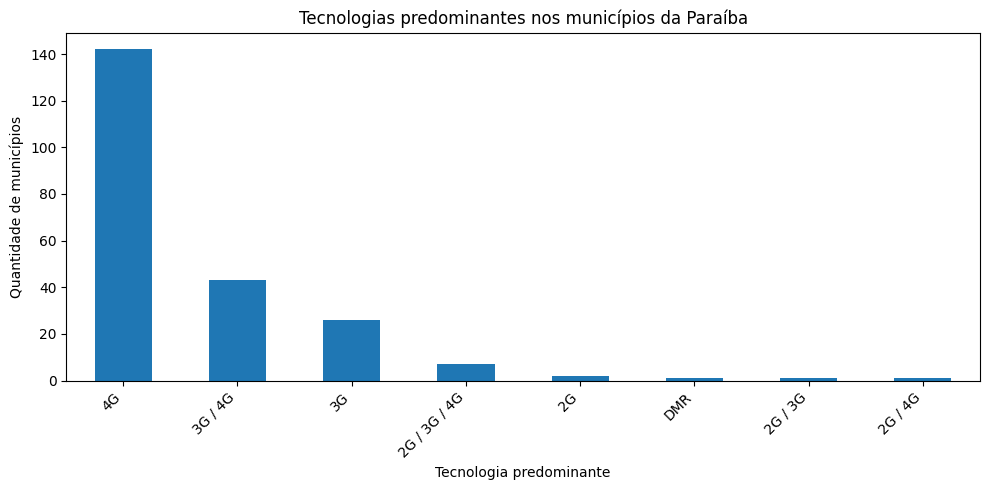

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Conferência da base
print("Municípios:", len(base_final))
print("Variáveis:", len(base_final.columns))

# Tecnologias predominantes
print("\nTecnologias predominantes:")
print(
    base_final["tecnologia_predominante"]
    .value_counts()
    .to_string()
)

# Presença de estações 5G
municipios_5g = (base_final["estacoes_5g"] > 0).sum()
percentual_5g = municipios_5g / len(base_final) * 100

print(f"\nMunicípios com 5G: {municipios_5g}")
print(f"Percentual: {percentual_5g:.2f}%")

# Municípios com mais estações licenciadas
top10 = base_final.nlargest(10, "total_estacoes")[
    ["municipio", "total_estacoes", "estacoes_4g", "estacoes_5g"]
]

display(top10)

# Gráfico das tecnologias predominantes
base_final["tecnologia_predominante"].value_counts().plot(
    kind="bar",
    figsize=(10, 5),
    title="Tecnologias predominantes nos municípios da Paraíba"
)

plt.xlabel("Tecnologia predominante")
plt.ylabel("Quantidade de municípios")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

total_municipios = len(base_final)
com_5g = (base_final["estacoes_5g"] > 0).sum()
sem_5g = total_municipios - com_5g

predominio_4g = (
    base_final["tecnologia_predominante"] == "4G"
).sum()

print("CONCLUSÃO DA ANÁLISE\n")

print(
    f"Foram analisados {total_municipios} municípios "
    "da Paraíba, reunindo informações demográficas "
    "e registros de infraestrutura de telecomunicações."
)

print(
    f"\nDesses municípios, {com_5g} possuem estações "
    f"5G registradas e {sem_5g} não possuem registros "
    "de estações 5G na base analisada."
)

print(
    f"\nO 4G aparece como tecnologia predominante "
    f"isolada em {predominio_4g} municípios."
)

print(
    "\nOs resultados mostram diferenças na infraestrutura "
    "de telecomunicações registrada entre os municípios. "
    "Entretanto, a existência de estações licenciadas "
    "não comprova cobertura, qualidade ou acesso efetivo "
    "à internet pela população."
)

print(
    "\nEsses indicadores podem contribuir para estudos "
    "sobre desigualdade territorial e acesso à informação, "
    "mas não permitem, isoladamente, concluir que existe "
    "uma relação causal com a educação financeira."
)


CONCLUSÃO DA ANÁLISE

Foram analisados 223 municípios da Paraíba, reunindo informações demográficas e registros de infraestrutura de telecomunicações.

Desses municípios, 72 possuem estações 5G registradas e 151 não possuem registros de estações 5G na base analisada.

O 4G aparece como tecnologia predominante isolada em 142 municípios.

Os resultados mostram diferenças na infraestrutura de telecomunicações registrada entre os municípios. Entretanto, a existência de estações licenciadas não comprova cobertura, qualidade ou acesso efetivo à internet pela população.

Esses indicadores podem contribuir para estudos sobre desigualdade territorial e acesso à informação, mas não permitem, isoladamente, concluir que existe uma relação causal com a educação financeira.


In [ ]:

import os

caminho_zip = "/content/xlsx_licenciamento_2474ff2932041629ddab15bee68b4e43.zip"

print("Arquivo encontrado:", os.path.exists(caminho_zip))


Arquivo encontrado: True
